**New voltage extension:** [MPC planning and learned LLM response selection](LLM_Response_Selection.ipynb) ([reading version](LLM_Response_Selection.html)) adds explicit MPC/SAC initial candidates, three real model responses, voting, a trained contextual bandit, held-out comparisons and AC model-transfer checks. Read E1–E8 after the voltage methods. This notebook retains its own original experiment and timing scope.



# Agentic grid workflows: from the control room to a checked recommendation

**Three hours · one exact checkpoint sequence · two electrical model routes · three use cases.**

Open the [presentation with gradual reveals](latex_slides/Agentic_Grid_Workshop.pdf) or [completed-slide handout](latex_slides/Agentic_Grid_Workshop_Handout.pdf). Run this notebook top to bottom. Slide labels refer to the metadata checkpoint on each code cell; all slide excerpts are extracted from these exact sources. This edition uses a genuinely continuous **SAC** actor and a continuous **MPC** plan in the main voltage workflow. Earlier DQN studies remain historical supplemental evidence.

Each use case is a complete chapter: **operating problem → numerical method → agent stages → named baseline → measured outcome and limits**. Voltage support includes its SAC/MPC agent trace before restoration starts. Restoration includes its operator-language study. Cyber response includes its own estimator/control comparison.

## Before the use cases: the workflow at the operator's desk

![AI-generated control-room concept; illustrative, not a deployed system](figures/control_room_concept.png)

An operator asks for an outcome and gives restrictions. The workflow must preserve those restrictions, call a suitable numerical method, inspect the result, and return an understandable recommendation. An **agent role** is a responsibility with permitted decisions. **Llama** is a language capability served locally through **Ollama**. **SAC, MPC, power flow, MILP and WLS** are different numerical tools. Separate prompts to one model do not constitute independent expert consensus.

Follow one decision: **request → Awareness → Planning → Execution proposal → Simulation → Verification → bounded Recovery → Explanation → human review**. A failed check feeds back to a permitted tool or a review request. The language model cannot create a passing current measurement, change an operating limit, or acknowledge for the operator.

| Control-room responsibility | What this lesson implements | What a deployment would additionally need |
|---|---|---|
| Supply information and limits | Structured synthetic case and model provenance | Utility telemetry/topology interfaces and data-quality processes |
| Propose and check an action | SAC/MPC or the case-specific numerical tool, followed by deterministic checks | Validation in the intended network, operating conditions and equipment scope |
| Decide what happens next | Bounded fixed or Llama tool choice; recorded response | Approved operating policies and tested exception handling |
| Human interaction | Inspect evidence, correct restrictions, request further review, or record local acknowledgment | Authenticated roles and a separate authorized dispatch process |

The proposed deployment is an **advisory application next to ADMS/SCADA**. It receives information and returns evidence for review; this notebook has no field-command interface. A sensible evaluation sequence is replay, shadow operation, then a supervised pilot. Whether it reduces workload or errors requires a human study. [Parasuraman et al., human interaction with automation](https://doi.org/10.1109/3468.844354), [Pratt et al., ADMS test bed](https://www.nlr.gov/docs/fy19osti/73705.pdf), [Yao et al., ReAct](https://arxiv.org/abs/2210.03629).

The illustration is AI-generated; [its complete prompt and provenance](figures/AI_Illustration_Provenance.md) are included. Diagrams are explanatory; numerical plots below come from actual code outputs.


### Scientific reading companion

The slides now define equation symbols on the page and compare published agentic frameworks before the use cases. Read [recent frameworks and their specific advantages](appendix/Recent_Agentic_AI_Literature.md), [how to read the equations and comparisons](appendix/Reading_Equations_and_Evidence.md), and [exact recorded Llama responses for all three cases](appendix/Case_Agent_Responses.md). Literature results and this tutorial's measured outcomes are identified separately.

**Implementation boundary.** The eight responsibilities are sequential roles around one local Llama model and deterministic engineering tools. Role separation helps inspect the decision; it is not independent expert consensus. The package uses these architectural patterns directly in Python and does not depend on the orchestration frameworks discussed in the literature comparison.

| Time | Learning task | Checkpoints |
|---|---|---|
| 0–20 min | Control room, agent roles, methods and human authority | Concepts before cases |
| 20–35 min | Inspect the workflow and selected electrical model | S1–S2, W1–W2, M1 |
| 35–85 min | Voltage support: method, agent workflow and baseline comparison | V1–V5, A1–A2 |
| 85–95 min | Break | — |
| 95–135 min | Restoration: method, workflow, language benefit and baseline | R1–R5 |
| 135–165 min | Cyber response: method, workflow and baseline comparison | C1–C4 |
| 165–180 min | Model comparison and human review | F1–F2 |

**Preparation before class.** Install Python 3.12 and `requirements_linear.txt` or `requirements.txt`, then start Jupyter in this directory. Ollama should already have `llama3.1:8b`. The saved SAC actor runs in NumPy; PyTorch/SB3 are needed only for optional training via `requirements_training.txt`. A1 uses actual local Llama calls by default. Explicit `LIVE_LLM=False` selects recorded responses; no reply is invented. The synthetic Greensboro feeder covers one area, not the city. The small restoration and cyber networks are separate teaching models.


<!-- proposal-complete-route -->
**Complete proposal workflow:** learn the numerical methods in this notebook, then run the matching case in [Proposal_Complete_Workflow.ipynb](Proposal_Complete_Workflow.ipynb): P2–P3 after voltage/A2, P4–P5 after restoration/R5, P6 after cyber/C4, and P7–P8 at operator review.

The five core modules are **Awareness, Planning, Simulation, Verification, and LLM Optimizer**. The original A/R/C traces illustrate initial bounded supervisors; the P notebook adds actual feedback-driven refinement and feasible ranking. It retains a matched fixed-search baseline, exact returned Llama explanations, both model scopes, and measured latency. The P notebook defaults to saved evidence; explicit live mode executes new calls.


**Expanded slide companion:** [Agent traces and latency](Agent_Trace_and_Latency.ipynb) follows T1–T9 with exact returned Llama reasons, stage tables, tokens, recorded client/server timings and paired plots. The 137-frame deck comprises 80 core frames for three hours, 48 optional code/detail frames and nine reference frames. Existing checkpoint code and saved outputs below are unchanged.


## S1–S2 · Prepare one reproducible route

The same public functions accept either electrical backend. Begin with the transparent Python model; the OpenDSS audience changes one setting. A saved notebook shows one completed run. Rerunning creates new numerical outputs and a separate timestamped Llama journal.

**S1.** Set the backend and whether to request new local Llama responses.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Image
from src.standard_formulations import PQBackend, run_voltvar, solve_restoration_milp, run_wls_demo
from src.stage_workflow import ElectricalModel, cases, run_stages
from src.continuous_control import (ContinuousPlant, cases as continuous_cases,
    load_policy as load_continuous_policy, sac_proposal, verify_control,
    optimize_mpc as optimize_continuous_mpc)
from src.continuous_workflow import (workflow_roles, request_contract, review_requirements,
    ContinuousLlama, run_continuous_workflow, point_summary)
from src.workshop_review import SCHEMA, comparison_rows, save_workshop_run
from src.workshop_display import (read_record, show_trace, table_rows, plot_voltage,
    plot_continuous_checks, plot_restoration, plot_cyber, plot_trusted_control)
ROOT = Path.cwd()
BACKEND = 'lindistflow3'  # OpenDSS audience: change to 'opendss'.
LIVE_LLM = True          # False explicitly selects recorded continuous-workflow responses.
assert (ROOT / 'data/lindistflow3_network.json').exists()
assert BACKEND in ('lindistflow3', 'opendss')
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
from src.case_comparisons import voltage_comparison, restoration_language_comparison, cyber_comparison


In [2]:
import scipy
network = json.loads((ROOT / 'data/lindistflow3_network.json').read_text())
casebook = {case.id: case for case in cases()}
continuous_casebook = {case.id: case for case in continuous_cases()}
training = json.loads((ROOT / 'models/continuous_sac/training.json').read_text())
print('Python', platform.python_version(), '| NumPy', np.__version__, '| SciPy', scipy.__version__)
print('Selected model:', BACKEND, '| Saved policy:', training['configuration']['algorithm'])
print('Training transitions:', training['configuration']['steps'], '| Seed:', training['configuration']['seed'])
print('Continuous actor provenance:', training['actor_sha256'])
print('Synthetic data and overlays: data/DATA_SOURCE.md; model limits: appendix/Scientific_Notes.md')


Python 3.12.14 | NumPy 2.5.3 | SciPy 1.18.1
Selected model: lindistflow3 | Saved policy: Stable-Baselines3 SAC
Training transitions: 12000 | Seed: 23
Continuous actor provenance: 9e6830061b43784dbdc0eb6ed350e604117e804970cfc41c253b4d1541767293
Synthetic data and overlays: data/DATA_SOURCE.md; model limits: appendix/Scientific_Notes.md


## W1–W2 · Inspect the framework before running a use case

W1 reads the actual stage/method definitions used by the new continuous workflow. W2 displays its structured operating request and human readback requirements. These are inspectable program objects, not a generated explanation of an unknown process.

The current-reserve case asks for 80% of nominal line rating. A result checked at 100% would answer a different request. The human later reviews the proposed P/Q, the allowance, the model scope and the failed attempts. Readback records review; it does not grant operating authority.


In [3]:
from src.proposal_workflow import stage_contract
display(pd.DataFrame(stage_contract()))


,proposal_module,method,output
0,Awareness Agent,Numerical telemetry/alarm summary and declared...,"State, topology, availability, forecast and mo..."
1,Planning Agent,Model-free policy and/or model-based candidate...,Explicit candidate controls with immutable ope...
2,Simulation Agent,"Fresh OpenDSS, three-phase LinDistFlow or decl...",Candidate-specific numerical consequences and ...
3,Verification Agent,Independent numerical and policy checks,"PASS or rejection reasons, scoped to the model..."
4,LLM Optimizer,"Llama critique, bounded repair/refinement and ...",A revised candidate for rechecking and an audi...


In [4]:
contract = request_contract(BACKEND, continuous_casebook['P3_current_reserve'])
display(contract)
display(review_requirements(contract))


{'case': {'id': 'P3_current_reserve',
  'forecast_loads': (1.0, 0.94, 1.06),
  'rating_fraction': 0.8,
  'previous': (0.25, 0.0)},
 'backend': 'lindistflow3',
 'tool_interface_version': '1.1',
 'objective': 'Retain PV with voltage regulation, reactive-effort and control-movement costs',
 'control': 'Shared p_g=a*S_g, q_g=b*S_g; real-valued a,b',
 'voltage_limits_pu': [0.95, 1.05],
 'allowed_current_percent_of_nominal': 80.0,
 'maximum_candidates': 2,
 'data_source': 'Synthetic scenario and model-generated evidence; no live SCADA',
 'authority': 'Advisory simulation only; human review cannot override failed checks'}

{'requested_current_allowance_percent': 80.0,
 'action_to_read_back': 'Actual proposed P/Q and participation factors',
 'scope_to_confirm': 'lindistflow3',
 'remaining_questions': ['Model coverage',
  'Measurement trust',
  'Protection and implementation authority'],
 'state': 'PENDING',
 'dispatch_authorized': False}

## M1 · Predict an operating point before choosing one

Power flow predicts voltages and currents for a specified setting. Optimization chooses a setting. All 930 PV systems share two continuous participation factors, $p_g=aS_g$ and $q_g=bS_g$. Begin with $[a,b]=[0.25,0]$ and inspect what the model actually checked.

OpenDSS evaluates the supplied unbalanced AC network. The Python three-phase LinDistFlow route evaluates coupled MV phases with aggregate interfaces; it omits internal LV constraints. A passing result is specific to that scope. [EPRI OpenDSS](https://opendss.epri.com/PowerFlow.html), [Gan and Low (2014)](https://arxiv.org/abs/1406.3054).

In [5]:
plant = ContinuousPlant(BACKEND)
smoke = plant.solve([0.25, 0.0])
display(point_summary(smoke))
print('Fresh first-action check:', verify_control(smoke))


{'control': [0.25, 0.0],
 'p_actual_kw': 1962.6116427432307,
 'q_actual_kvar': 0.0,
 'vmin': 1.0100665335210879,
 'vmax': 1.03,
 'max_line_utilization_pct': 46.142559403234706,
 'max_allowed_current_pct': 46.142559403234706,
 'accepted': True,
 'violations': {'voltage_low': 0,
  'voltage_high': 0,
  'line_current': 0,
  'inverter_capability': 0,
  'dispatch_tracking': 0},
 'scope': 'MV phases only; ideal LV aggregation',
 'converged': True,
 'backend': 'lindistflow3',
 'load_mult': 1.0,
 'rating_fraction': 1.0,
 'fresh_model_solve': True}

Fresh first-action check: []


## V1–V3 · Voltage support with continuous inverter controls

### The operator's question: how much PV can we retain?

Think of active power as energy delivery and reactive power as an additional way to influence voltage. Both share the inverter's capacity and affect line current. Before running V1, predict whether improving voltage alone guarantees that every current limit passes. Read the results to test that prediction.

**Teaching bridge:** first choose controls for one snapshot. Later, V4 retains shared continuous P/Q controls, adds a forecast horizon and a movement penalty, and compares model-based MPC with a reward-trained continuous SAC actor.

**Concept.** Active power delivers energy; reactive power changes voltage and current without net active-energy delivery. Curtailment has a cost, but reactive absorption also uses inverter capacity and may increase current. Check individual phases, not just a feeder average.

A widely used voltage-control OPF balances voltage deviation, curtailment and control effort subject to the electrical model, voltage/current limits and inverter capability:

$$\min\sum_{i,\phi}w_v(v_{i\phi}-v^{\rm ref})^2+\sum_g w_p(p_g^{\rm av}-p_g)^2+w_q q_g^2,
\quad \underline v\leq v\leq\overline v,\quad |I|\leq\overline I,\quad p_g^2+q_g^2\leq S_g^2.$$

**Our executable reduction.** All inverter setpoints share two participation factors, $p_g=aS_g$, $q_g=bS_g$. The high-irradiance teaching overlay sets available active power to $S_g$. We minimize $(1-a)^2+0.05b^2+10\operatorname{mean}[(v-1.01)^2]$, where $v$ now denotes voltage magnitude in p.u. Sequential sensitivity QPs use bounded steps and a 32-sided polygon inside the capability circle, with actual per-device reactive limits. Every proposed step is checked by the selected backend. This is restricted, local continuous optimization; it is neither independent optimal control of every device nor a global AC optimum.

The **unoptimized baseline** is $a=1,b=0$. This comparison measures the benefit of numerical optimization. It cannot establish an advantage from Llama. To attribute an agent contribution, keep the same optimizer and compare supervisors later.

**Predict:** which limit will bind first? **V1** solves the snapshot; **V2** plots the actual samples. Sorted samples reveal extrema, not geographic position. [Maharjan et al., predictive voltage control](https://doi.org/10.1109/TSTE.2020.3001115).


In [6]:
voltage = run_voltvar(BACKEND)
columns = ['p_actual_kw', 'q_actual_kvar', 'vmin', 'vmax',
           'max_line_utilization_pct', 'objective', 'accepted']
display(pd.DataFrame({name: {key: voltage[name][key] for key in columns}
                     for name in ('baseline', 'optimized')}).T)
display({'scope': voltage['scope'], 'validation': voltage['validation'],
         'remaining_violations': voltage['optimized']['violations']})


,p_actual_kw,q_actual_kvar,vmin,vmax,max_line_utilization_pct,objective,accepted
baseline,7850.446571,0.0,1.03,1.048024,60.82223,0.007605,True
optimized,7727.470994,-1248.591988,1.022481,1.037013,65.329358,0.005486,True


{'scope': 'MV phases only',
 'validation': {'fresh_backend_accepted': True, 'backend_solves': 28},
 'remaining_violations': {'voltage_low': 0,
  'voltage_high': 0,
  'line_current': 0,
  'inverter_capability': 0,
  'dispatch_tracking': 0}}

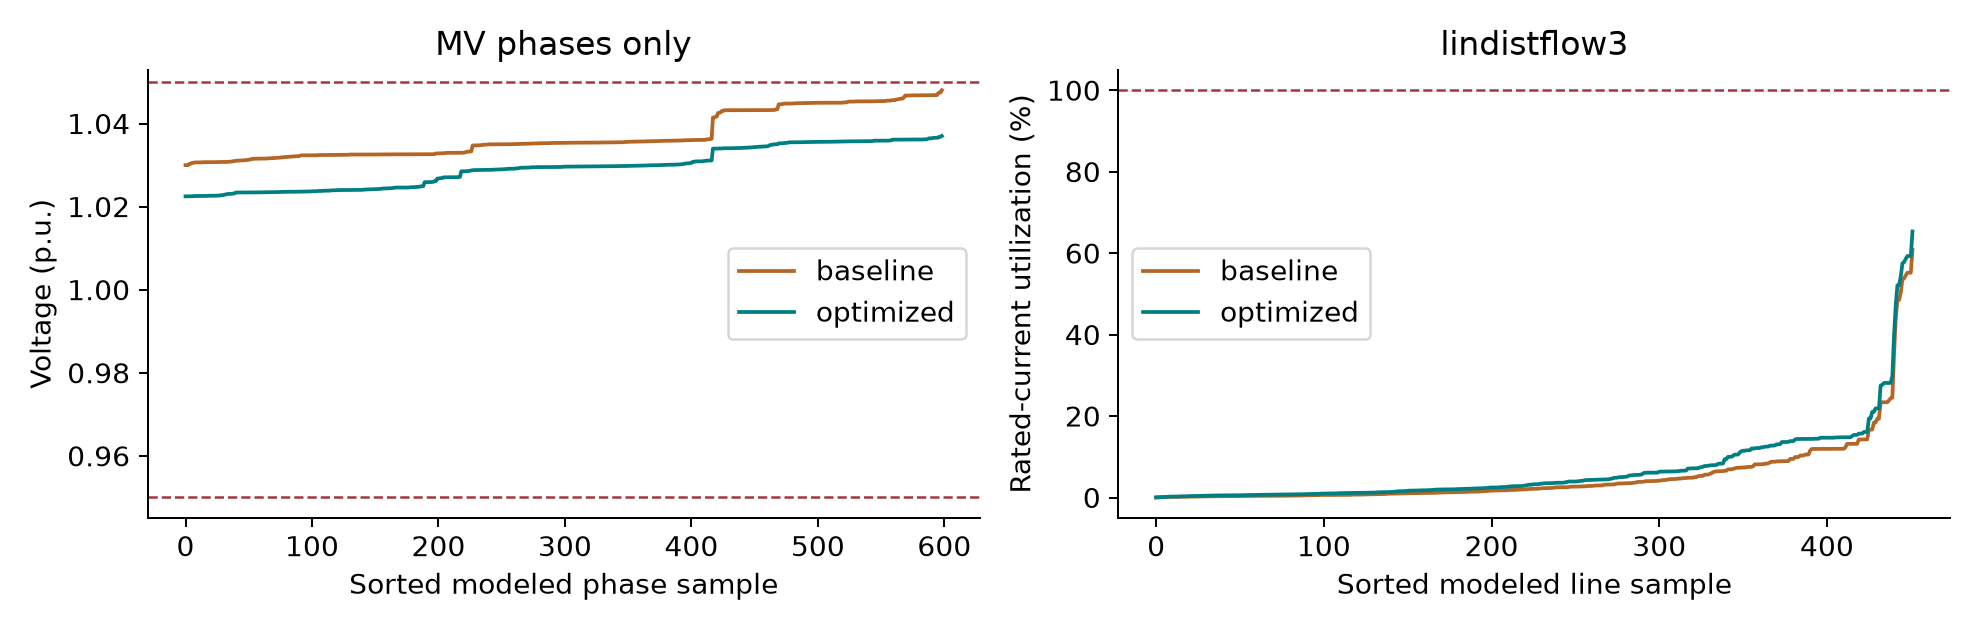

,iteration,linearization_control,qp_success,qp_message,qp_control,qp_constraint_violation,objective_before,disposition,line_search_fraction,control,objective_after,validation
0,1,"[0.25, 0.0]",True,Optimization terminated successfully,"[0.55, -0.08702222782810104]",0.0,0.562784,accepted_fresh_backend_solve,1.0,"[0.55, -0.08702222782810104]",0.203894,"{'voltage_low': 0, 'voltage_high': 0, 'line_cu..."
1,2,"[0.55, -0.08702222782810104]",True,Optimization terminated successfully,"[0.8500000000000001, -0.14682252027576453]",0.0,0.203894,accepted_fresh_backend_solve,1.0,"[0.8500000000000001, -0.14682252027576453]",0.026273,"{'voltage_low': 0, 'voltage_high': 0, 'line_cu..."
2,3,"[0.8500000000000001, -0.14682252027576453]",True,Optimization terminated successfully,"[0.9842905535814598, -0.15950068618245003]",0.0,0.026273,accepted_fresh_backend_solve,1.0,"[0.9842905535814598, -0.15950068618245003]",0.005486,"{'voltage_low': 0, 'voltage_high': 0, 'line_cu..."
3,4,"[0.9842905535814598, -0.15950068618245003]",True,Optimization terminated successfully,"[0.9843352125269466, -0.15904725629959238]",0.0,0.005486,accepted_fresh_backend_solve,1.0,"[0.9843352125269466, -0.15904725629959238]",0.005486,"{'voltage_low': 0, 'voltage_high': 0, 'line_cu..."
4,5,"[0.9843352125269466, -0.15904725629959238]",True,Optimization terminated successfully,"[0.9843352125269466, -0.15904725629959238]",0.0,0.005486,accepted_fresh_backend_solve,1.0,"[0.9843352125269466, -0.15904725629959238]",0.005486,"{'voltage_low': 0, 'voltage_high': 0, 'line_cu..."


In [7]:
plot_voltage(voltage)
display(pd.DataFrame(voltage['solver_trace']))


**Read the result.** The MV starting point is already feasible: its optimization improves a declared tradeoff. The same setting may fail a fuller AC audit because the two models cover different devices. Do not interpret retained PV alone as evidence of a superior full-feeder controller.

**Exercise (3 min).** In a scratch cell, compare `PQBackend(BACKEND).solve([0.8, 0.0])` with `PQBackend(BACKEND).solve([0.8, -0.1])`. Hold active participation fixed and change reactive absorption. Predict the voltage and current changes, then inspect the returned violations. Both routes support these calls. A computed point need not pass the limits.


In [8]:
standard = read_record('standard_formulations.json')
comparison = []
for backend, result in standard['voltvar'].items():
    for evaluation in ('baseline', 'optimized', 'reference_full_ac_audit'):
        if evaluation in result:
            comparison.append({'backend': backend, 'evaluation': evaluation,
                               **{key: result[evaluation][key] for key in
                                  ('vmin', 'vmax', 'max_line_utilization_pct', 'accepted')}})
print('RECORDED results and separate full-AC audit:')
display(pd.DataFrame(comparison))


RECORDED results and separate full-AC audit:


,backend,evaluation,vmin,vmax,max_line_utilization_pct,accepted
0,opendss,baseline,1.019639,1.108207,283.036633,False
1,opendss,optimized,1.004723,1.043224,99.891299,True
2,lindistflow3,baseline,1.030000,1.048024,60.822230,True
3,lindistflow3,optimized,1.022481,1.037013,65.329358,True
4,lindistflow3,reference_full_ac_audit,1.010868,1.087074,288.237096,False


## V4–V5 · Continuous SAC proposals and an MPC horizon

**The action remains continuous.** SAC produces two real numbers $z\in[-1,1]^2$. The actuator map is

$$a=(z_1+1)/2,\qquad b=z_2\min\{0.44,\sqrt{1-a^2}\}.$$

This enforces inverter capability and reactive bounds without rounding to a PV-cap catalog. It does **not** enforce network voltage or line current. The shared participation variables do not represent independently optimized controls at every inverter.

**SAC learns from reward.** It is an off-policy actor–critic with replay, twin critics and an entropy term. Here Stable-Baselines3 trains a squashed-Gaussian actor for 12,000 transitions using a fixed entropy coefficient of 0.005. Training uses a declared cubic approximation to AC responses (240 fitting points, 48 separate fit-validation points). The training objective uses the stage cost plus penalties for estimated violations. It uses no MPC action labels. The final seed-23 actor is exported to NumPy and checked against the original trained actor.

**PPO is another continuous-action option.** PPO instead uses on-policy rollouts and a clipped policy-ratio objective. This lesson executes SAC only; it does not claim a SAC-versus-PPO experiment. [SAC, Haarnoja et al. (2018)](https://proceedings.mlr.press/v80/haarnoja18b.html), [SAC algorithm details](https://arxiv.org/abs/1812.05905), [PPO, Schulman et al. (2017)](https://arxiv.org/abs/1707.06347), [SB3 SAC documentation](https://stable-baselines3.readthedocs.io/en/master/modules/sac.html).

**MPC solves a continuous horizon.** With $u_k=[a_k,b_k]$, the executed objective is

$$\min_{u_0,u_1,u_2}\sum_{k=0}^{2}0.98^k\left[(1-a_k)^2+0.05b_k^2+10\,\mathrm{mean}((v_k-1.01)^2)+0.05\lVert u_k-u_{k-1}\rVert_2^2\right].$$

Local sensitivity QPs enforce model voltage, allowed current and a conservative inscribed capability polygon; fresh model evaluations check all forecast points. These are local numerical plans with known forecasts, not global AC optima or stability guarantees. Only their first action is proposed to the workflow. [Rawlings, Mayne and Diehl, MPC](https://sites.engineering.ucsb.edu/~jbraw/mpc/MPC-book-2nd-edition-4th-printing.pdf).

**Three predeclared tests.** P1 uses nominal load, P2 a changing load trajectory, and P3 an 80% current allowance. The same trained SAC weights are used on both model routes. Exact test trajectories are held out; this remains the same feeder and a small authored test set. Nominal-current training makes P3 a constraint shift. V5 separates a raw SAC proposal from a freshly checked model-based action. The workflow gate checks the first action; it does not apply the old DQN value-gap rule.

Optional training is preparation outside the timed workshop: follow [Continuous_SAC_Training.ipynb](Continuous_SAC_Training.ipynb). The current notebook loads the supplied checkpoint and displays its actual learning curve.


,case,sac_control_a_b,mpc_control_sequence,mpc_horizon_cost,mpc_status
0,P1_nominal,"[0.3267212063074112, 0.004338037185370922]","[[0.959351319889684, -0.1120105567284857], [0....",0.043351,PLAN
1,P2_load_change,"[0.28694313764572144, -0.07433817327022553]","[[0.9696632925354193, -0.16015757404012718], [...",0.030253,PLAN
2,P3_current_reserve,"[0.33693869411945343, 0.030701177120208742]","[[0.9593489272052167, -0.11290652382907215], [...",0.043416,PLAN


One nominal-current OpenDSS response-surface SAC; same weights on both backends.


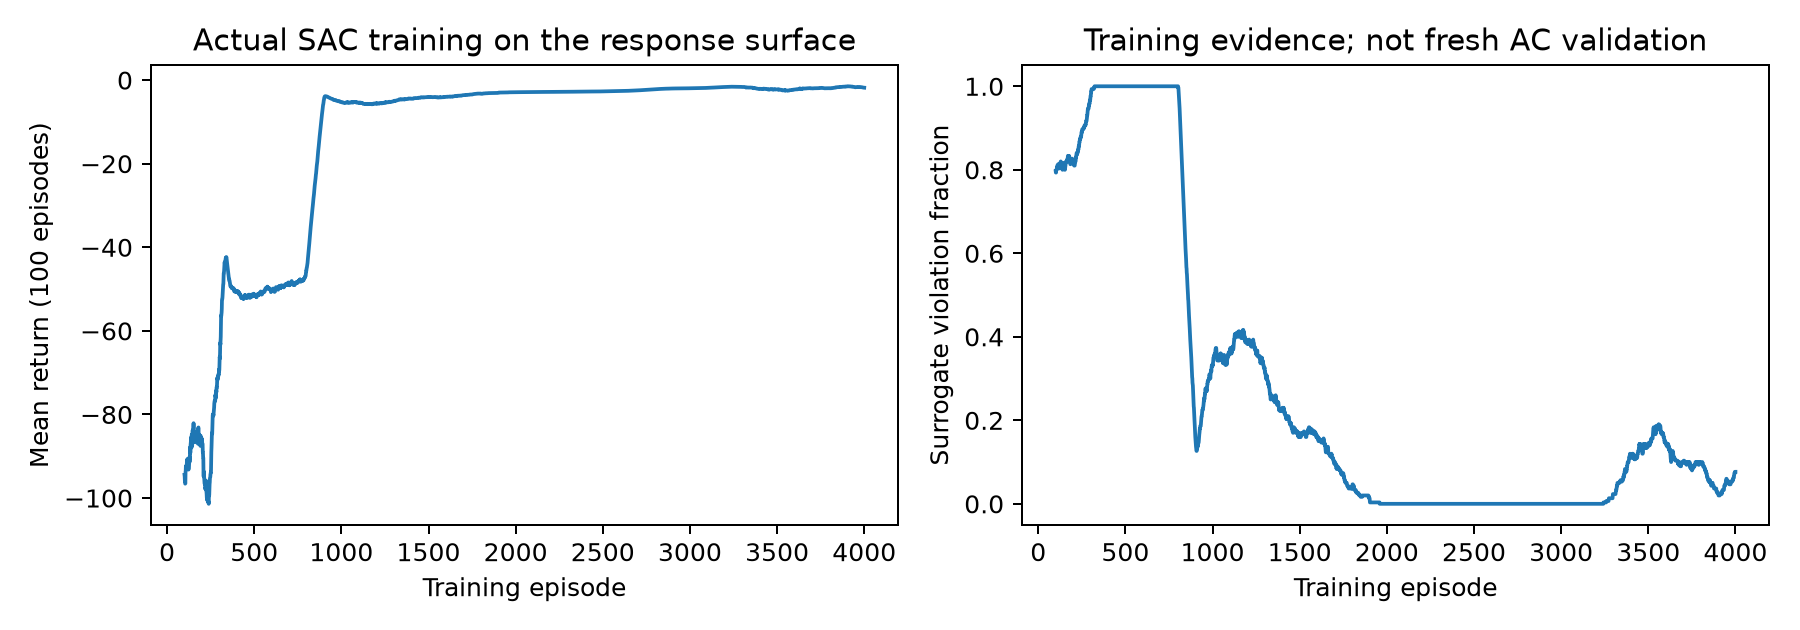

In [9]:
policy = load_continuous_policy()
plans = {key: optimize_continuous_mpc(case, BACKEND) for key, case in continuous_casebook.items()}
proposals = {key: sac_proposal(case, policy) for key, case in continuous_casebook.items()}
display(pd.DataFrame([{'case': key, 'sac_control_a_b': proposals[key]['candidate']['control'],
    'mpc_control_sequence': plans[key]['control_sequence'], 'mpc_horizon_cost': plans[key]['objective'],
    'mpc_status': plans[key]['status']} for key in plans]))
print(proposals['P3_current_reserve']['training_scope'])
display(Image(filename=str(ROOT / 'figures/continuous_training.png')))


,case,SAC_failed_checks,MPC_failed_checks,MPC_horizon_feasible
0,P1_nominal,[],[],True
1,P2_load_change,[],[],True
2,P3_current_reserve,[],[],True


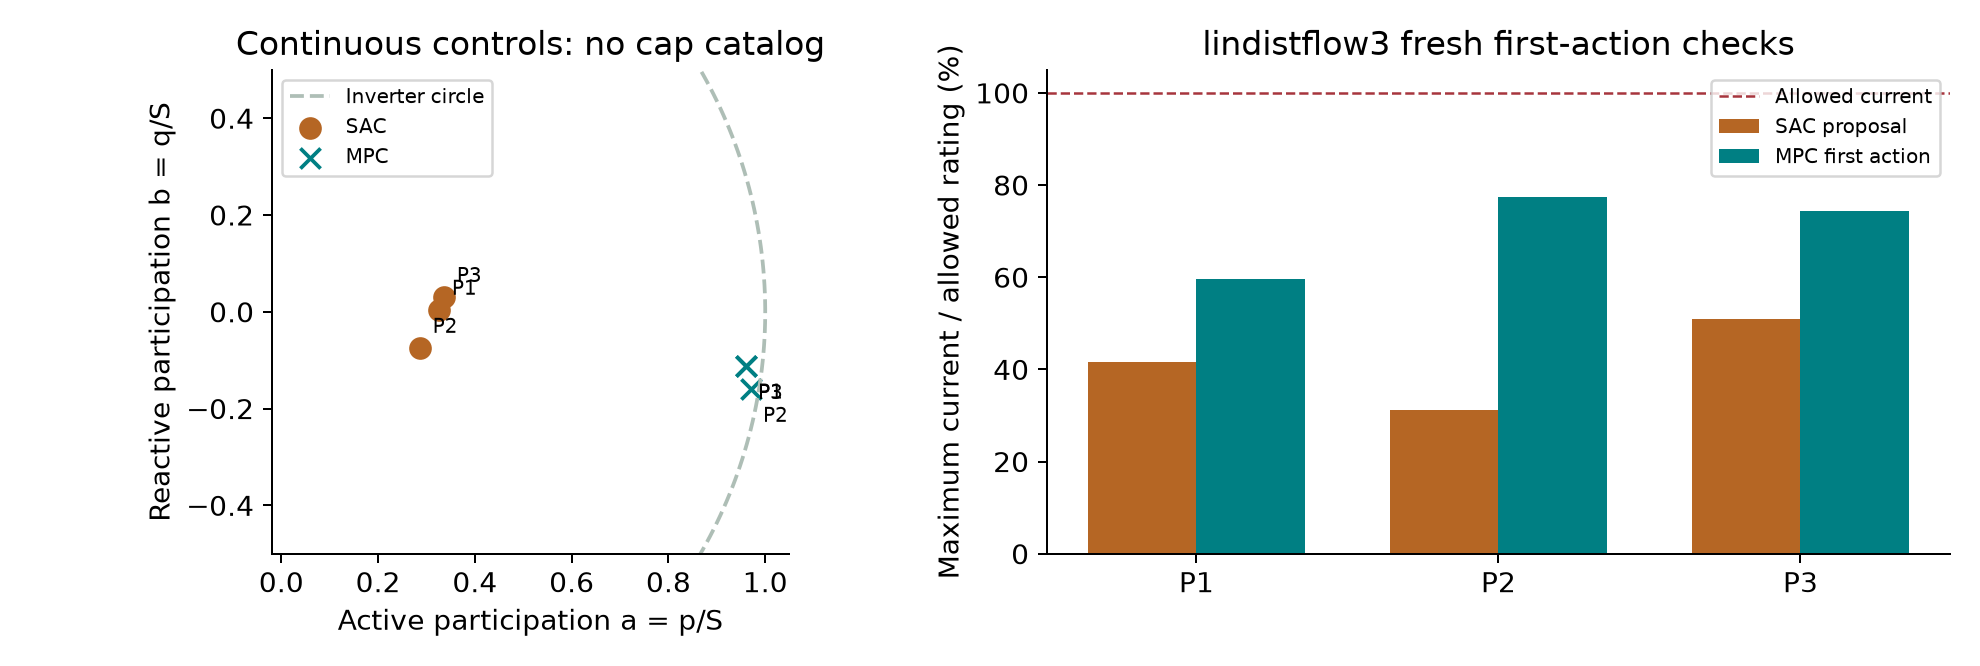

In [10]:
checks = []
for key, case in continuous_casebook.items():
    raw = plant.solve(proposals[key]['candidate']['control'], case.forecast_loads[0], case.rating_fraction)
    first = plans[key]['candidate']
    mpc_point = None if first is None else plant.solve(first['control'], case.forecast_loads[0], case.rating_fraction)
    checks.append({'case': key, 'sac_point': point_summary(raw), 'sac_failures': verify_control(raw, case),
        'mpc_point': point_summary(mpc_point) if mpc_point else None,
        'mpc_failures': verify_control(mpc_point, case), 'mpc_horizon_feasible': plans[key].get('horizon_feasible', False)})
display(pd.DataFrame([{'case': r['case'], 'SAC_failed_checks': r['sac_failures'],
    'MPC_failed_checks': r['mpc_failures'], 'MPC_horizon_feasible': r['mpc_horizon_feasible']} for r in checks]))
plot_continuous_checks(checks, BACKEND)


**Prediction check.** Explain why mapping an action inside the inverter circle does not guarantee a passing line-current check. P3 changes the allowable current from the nominal training condition. Inspect the actual raw proposal and the fresh checker result rather than assuming a failure or a benefit.

## A1–A2 · Voltage support: the agent workflow and its baselines

We now run those same eight roles on P3. Both supervisors start from the same continuous SAC proposal, share the same precomputed MPC contingency plan, and freshly check every selected candidate. The fixed rule chooses MPC after a rejected SAC point. Llama chooses only between the permitted next step and REVIEW. The common initial candidate is an explicit paired-design choice, not a hidden override of a language decision.

A1 makes actual local Llama Planner, Recovery (when needed), and Explanation calls. Other stages use the numerical methods shown in W1. The simulation and verification stages return the exact first-action evidence; MPC's planned-horizon checks are labeled separately. No stage authorizes physical actuation. A Llama response may stop for review: preserve that observed outcome.

**Named baselines.** The raw SAC proposal shows what happens without a checking-and-recovery workflow. The fixed adaptive supervisor is the stronger conventional baseline: it uses exactly the same actor, MPC plan and verifier as Llama. A2 displays all three. A raw point can violate limits; both supervised routes can repair it. Equal repaired controls establish the value of verification and recovery, while leaving an incremental Llama control advantage unproven.


In [11]:
study_case = continuous_casebook['P3_current_reserve']
shared = {'proposal': proposals[study_case.id], 'plan': plans[study_case.id]}
fixed = run_continuous_workflow(study_case, BACKEND, method='fixed', **shared)
if LIVE_LLM:
    stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
    llama = ContinuousLlama(ROOT / 'results' / ('continuous_llama_' + BACKEND + '_' + stamp + '.json'))
    agentic = run_continuous_workflow(study_case, BACKEND, method='agentic', llama=llama, **shared)
    agent_source = 'NEW local Llama calls on continuous SAC/MPC workflow'
else:
    saved = read_record('workshop_run_' + BACKEND + '.json')
    assert saved['schema'] == SCHEMA
    agentic = saved['agentic']
    assert agentic['case_definition'] == json.loads(json.dumps(contract['case']))
    agent_source = 'RECORDED continuous workflow; no new Llama calls'
print(agent_source)
table_rows([fixed, agentic], ['case', 'backend', 'method', 'status', 'candidate', 'llm_calls'])


NEW local Llama calls on continuous SAC/MPC workflow


,case,backend,method,status,candidate,llm_calls
0,P3_current_reserve,lindistflow3,fixed,MODEL_RECOMMEND,"{'tool': 'SAC', 'control': [0.3369386941194534...",0
1,P3_current_reserve,lindistflow3,agentic,MODEL_RECOMMEND,"{'tool': 'SAC', 'control': [0.3369386941194534...",2


In [12]:
print('FIXED supervisor:')
show_trace(fixed)
print('AGENTIC supervisor:', agent_source)
show_trace(agentic)
display(pd.DataFrame(voltage_comparison(fixed, agentic)))


FIXED supervisor:


,stage,method,status,response_source
0,Awareness,Validate structured task and provenance,PASS,deterministic_method
1,Planning,Continuous MPC contingency plan + bounded stra...,PLAN,fixed_rule
2,Execution,Saved continuous SAC actor,PROPOSE,deterministic_method
3,Simulation,Fresh lindistflow3 evaluation of the exact pro...,EVALUATED,deterministic_method
4,Verification,"Declared voltage/current, action, inverter and...",PASS,deterministic_method
5,Recovery,At most one MPC fallback; Llama or fixed choice,SKIPPED,deterministic_method
6,Explanation,Deterministic evidence card + language focus,RECORDED,fixed_rule
7,Operator acknowledgment,Human readback bound to this record identity,PENDING,deterministic_method


AGENTIC supervisor: NEW local Llama calls on continuous SAC/MPC workflow


,stage,method,status,response_source
0,Awareness,Validate structured task and provenance,PASS,deterministic_method
1,Planning,Continuous MPC contingency plan + bounded stra...,PLAN,actual_local_llama
2,Execution,Saved continuous SAC actor,PROPOSE,deterministic_method
3,Simulation,Fresh lindistflow3 evaluation of the exact pro...,EVALUATED,deterministic_method
4,Verification,"Declared voltage/current, action, inverter and...",PASS,deterministic_method
5,Recovery,At most one MPC fallback; Llama or fixed choice,SKIPPED,deterministic_method
6,Explanation,Deterministic evidence card + language focus,RECORDED,actual_local_llama
7,Operator acknowledgment,Human readback bound to this record identity,PENDING,deterministic_method


,method,backend,case,proposal_tool,P_fraction,Q_fraction,simulated_P_kW,simulated_Q_kvar,maximum_current_pct_of_allowance,numerical_candidate_passed,candidate_failure_reasons,corrective_gate_used,workflow_status,LLM_calls,equipment_operated
0,Raw SAC proposal (audit only),lindistflow3,P3_current_reserve,SAC,0.336939,0.030701,2645.119216,241.017951,50.918255,True,,False,UNGATED_PROPOSAL,0,False
1,Conventional adaptive supervisor,lindistflow3,P3_current_reserve,SAC,0.336939,0.030701,2645.119216,241.017951,50.918255,True,,True,MODEL_RECOMMEND,0,False
2,Agentic supervisor,lindistflow3,P3_current_reserve,SAC,0.336939,0.030701,2645.119216,241.017951,50.918255,True,,True,MODEL_RECOMMEND,2,False


**Interpretation.** Identify which response came from Llama, which came from a numerical tool, and which came from a fixed check. An accepted continuous action can differ by model coverage. Equal fixed/agentic outcomes do not show an LLM optimization advantage. A review request is an observed decision, not automatically a superior outcome.

**Contract revision 1.1.** Both initial live Llama runs stopped at REVIEW before checking a candidate. The initial planner payload omitted the actual SAC proposal and left tool effects ambiguous. One disclosed revision supplies that proposal and defines verification as a numerical tool request, while REVIEW remains human escalation. Model settings, controls, limits and the fixed comparator are unchanged. The original records and exact replies are retained under `results/continuous_contract_pilot`; `results/continuous_contract_revision.json` documents the change. The current runs use 1.1. This interface-development revision is not a held-out test of improved performance.

**Voltage conclusion.** On the supplied AC P3 case, raw SAC reaches 111.97% of the allowed current; both supervised routes use an MPC replacement at 99.60%. The same raw point passes MV-only LinDistFlow. Current is relative to the 80% allowance. These are modeled first-action results; neither model pass nor Llama narration establishes field safety. Restoration next asks whether an operator's language can be translated into the right restrictions.


## Break · 85–95 minutes

State the benefit of the checked voltage workflow and whether Llama improved its numerical result over fixed adaptive rules. Keep the kernel running. Restoration is the next complete use case.


## R1–R5 · Restoration: from a fault to a checked plan and operator handoff

**Chapter route.** R1–R2 explain and solve a restoration MILP. R3 checks a restricted feeder catalog. R4 shows the actual agent stages and the fixed-supervisor result for the same MILP. R5 compares rule-based and selective-Llama interpretation of restoration requests before the unchanged feeder tools run.

### A fault changes the question

Voltage support selected setpoints on a fixed network. Now a failed path changes **which loads can be reached and supplied**. Picture a bus as a junction: power can pass through it while its own load stays disconnected. The six-node teaching graph lets us see those decisions before returning to the Greensboro feeder.

**Predict:** if a tie rating decreases, must every load downstream lose supply? Look for an alternative route and the difference between energizing a bus and picking up its load.

**Concept.** Fault isolation removes an unsafe path. Restoration chooses available branches and load pickup, subject to source connectivity, radiality and capacity. A bus may carry power to another bus while its own load remains disconnected. A final topology is not a safe chronological switching order.

A common formulation is mixed-integer optimization. Binary $y_i$ energizes buses, $s_i$ picks up loads and $z_e$ selects branches. In a single snapshot, maximize weighted served kW:

$$\max\sum_i w_i P_i^d s_i,\qquad s_i\leq y_i,\quad
-\overline P_e z_e\leq P_e\leq\overline P_e z_e,\quad
\sum_{e\in\delta^-(i)}P_e-\sum_{e\in\delta^+(i)}P_e=P_i^d s_i.$$

The power balance above applies at non-source buses; source injection supplies their total demand. Unavailable faulted edges have $z_e=0$. A fictitious commodity supplies one unit to every energized non-source bus; with $\sum_e z_e=\sum_i y_i-1$, this imposes a connected tree. The commodity is a connectivity proof, not electrical power. Edge count alone does not prevent disconnected cycles. The general electrical formulation also includes voltage, reactive flow and eligible sources.

**Executable reduction.** Six nodes and active-power capacities make the MILP transparent and small enough for independent enumeration. Nodes 2 and 5 have weight 10; other loads have weight 1. Finite weighting is a stated preference, not a general guarantee of strict critical-load priority. The second objective preserves maximum weighted pickup then minimizes energized-branch count, not the number of changes from a prior topology. We vary the tie 0–4 capacity from 220 to 100 kW. This graph is a teaching model, not the Greensboro feeder.

**R1** solves and verifies the primary optimum independently. **R2** shows selected graphs and load pickup. [Chen et al., service restoration MILP](https://doi.org/10.1109/TPWRS.2017.2720122), [Wang et al., radiality constraints](https://arxiv.org/abs/1912.05185).


In [13]:
restoration = {label: solve_restoration_milp(capacity)
               for label, capacity in [('normal', 220.), ('limited', 100.)]}
display(pd.DataFrame([{'case': label, **{key: row['milp'][key] for key in
                      ('served_kw', 'critical_served_kw', 'objective', 'mip_gap')},
                      'enumeration_agrees': row['agreement']}
                     for label, row in restoration.items()]))
display(pd.DataFrame(restoration['limited']['graph']['edges']))


,case,served_kw,critical_served_kw,objective,mip_gap,enumeration_agrees
0,normal,250.0,90.0,1060.0,0.0,True
1,limited,200.0,90.0,1010.0,0.0,True


,name,u,v,capacity_kw,available
0,source_healthy,0,1,300.0,True
1,faulted_segment,1,2,250.0,False
2,section_23,2,3,250.0,True
3,section_34,3,4,250.0,True
4,section_25,2,5,250.0,True
5,tie_04,0,4,100.0,True
6,tie_15,1,5,100.0,True


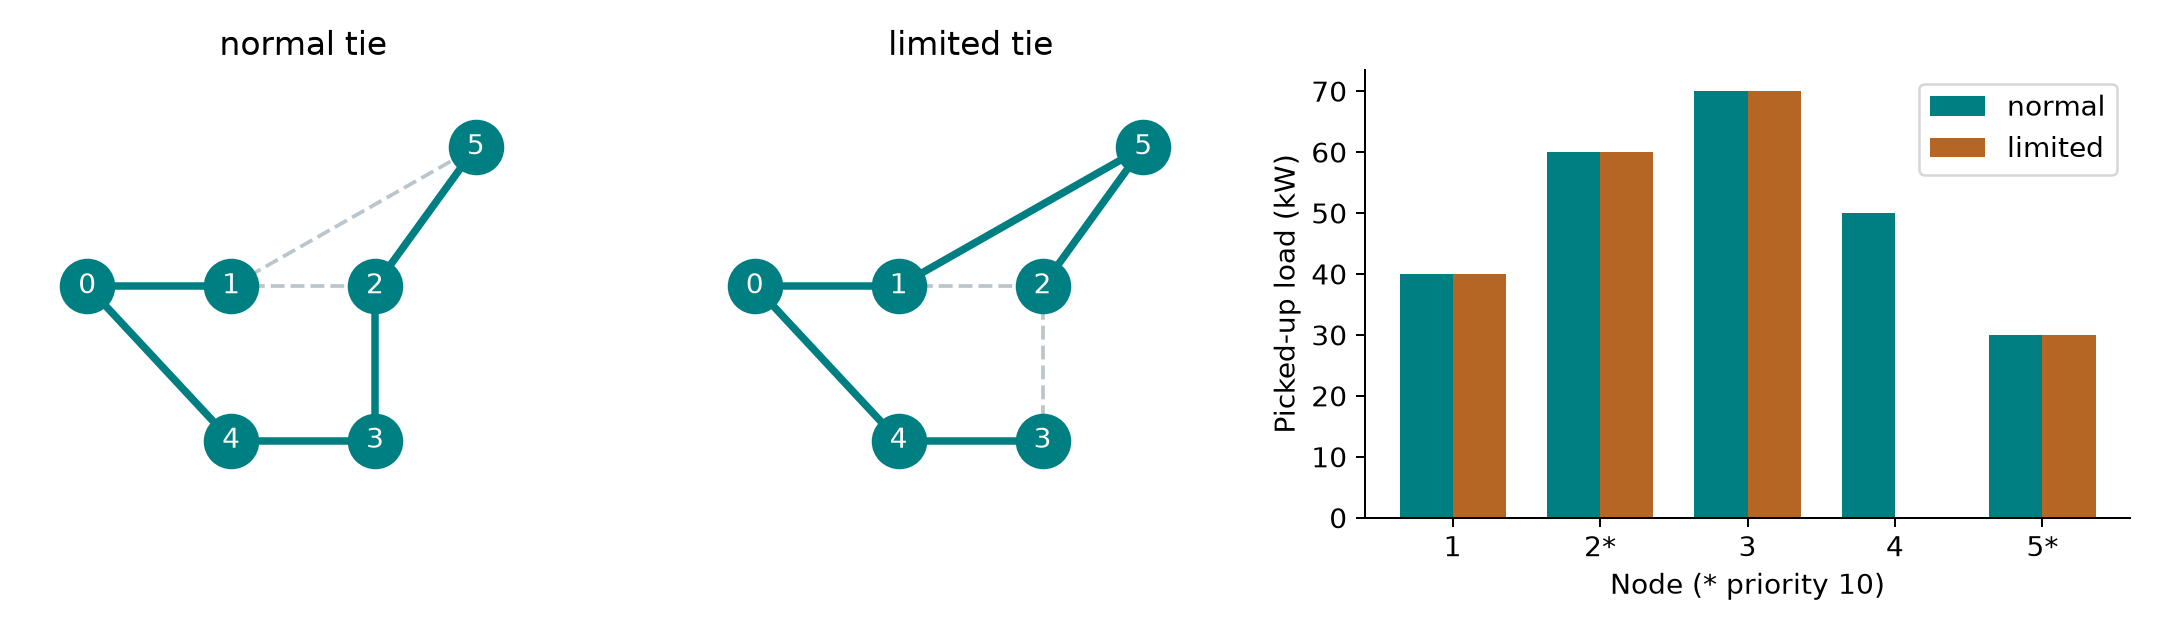

{'limited_pickup': [0, 1, 1, 1, 0, 1],
 'limited_closed_edges': ['source_healthy',
  'section_34',
  'section_25',
  'tie_04',
  'tie_15']}

In [14]:
plot_restoration(restoration)
display({'limited_pickup': restoration['limited']['milp']['pickup'],
         'limited_closed_edges': restoration['limited']['milp']['closed_edges']})


**Exercise (3 min).** Predict the effect of reducing tie 0–4 to 80 kW. Run `solve_restoration_milp(80.)` in a new scratch cell and check enumeration agreement. Explain why serving a transit bus's load and energizing the bus are separate decisions.

## R3–R4 · Return to the feeder, then inspect the restoration agent

**R3** applies the selected physical backend to Greensboro R1 and R2. Here the established frozen workflow searches a declared small catalog: short tie with discrete shedding fractions, or an available long tie. Its objective is served kW plus nine additional weights on critical kW. It is a physically checked catalog search, not a full-feeder MILP. R2 removes the long tie and PV option and restricts tie capacity. Keep these scopes separate from the graph experiment.

**R4** reads actual recorded Llama responses around the *standard MILP* method. This wrapper allows one numerical attempt with a pre-authorized method family. It demonstrates structured routing and explanation, not an adaptive repair experiment. Its numerical restoration solution passed, but its explanation selected `REVIEW`; that stopping decision is preserved.

In [15]:
electrical = ElectricalModel(BACKEND)
feeder_restoration = [run_stages(casebook[key], electrical, None, method='fixed')
                      for key in ('R1', 'R2')]
display(pd.DataFrame([{'case': row['case'], 'status': row['status'],
    'candidate': row['candidate'], **(row['metrics'] or {})} for row in feeder_restoration]))


,case,status,candidate,vmin,vmax,served_kw,unserved_kw,nominal_kw,critical_served_kw,critical_total_kw,pv_kw,losses_kw,mv_cycles,model_scope,backend,energized_bus_count,allowed_current_utilization_pct,loss_note
0,R1,MODEL_RECOMMEND,"{'tool': 'RESTORATION_SEARCH', 'pv_cap': 20.0,...",1.009116,1.03,4747.46756,0.00000,4747.46756,474.03975,474.03975,1765.0,42.452220,0,medium_voltage_only,lindistflow3,453,47.755140,Approximate MV I^2R reporting only; omitted fr...
1,R2,MODEL_RECOMMEND,"{'tool': 'RESTORATION_SEARCH', 'pv_cap': 0.0, ...",1.019527,1.03,1843.61355,2903.85401,4747.46756,474.03975,474.03975,0.0,14.919114,0,medium_voltage_only,lindistflow3,453,91.867215,Approximate MV I^2R reporting only; omitted fr...


In [16]:
standard_stages = read_record('standard_agent_workflow.json')
restoration_agent = next(row for row in standard_stages['runs']
                         if row['case'] == 'restoration' and row['supervisor'] == 'agentic')
print('RECORDED standard-MILP integration:', restoration_agent['status'])
show_trace(restoration_agent)


RECORDED standard-MILP integration: REVIEW


,stage,method,status,response_source
0,Awareness,Declared scenario/schema and model-coverage ch...,PASS,None
1,Planning,RESTORATION_MILP with fixed parameters,SOLVED,None
2,Execution proposal,Extract the numerical solution; no physical ac...,PROPOSED,None
3,Simulation,Independent graph enumeration,EVALUATED,None
4,Verification,Declared numerical success and modeled-constra...,PASS,None
5,Recovery,One numerical attempt; unsuccessful verificati...,NOT_NEEDED,None
6,Explanation,Numerical metric card and separately labeled e...,REVIEW,None
7,Operator acknowledgment,Human review of immutable result identity,PENDING,None


## R5 · Restoration: what benefit does the language agent add?

The same conventional restoration solver can only act automatically after the request has been expressed as usable restrictions. We compare a **fixed rule parser plus the numerical workflow** with a **selective Llama fallback plus that same numerical workflow**.

For **h06**, the operator asks to use the 0.25 km bypass at no more than 100 A, keep the 2 km bypass open and leave PV at zero. The rule parser requests clarification. Selective Llama supplies the correct restrictions; the unchanged search and fresh AC check return **1,843.61 kW served**, including **474.04 kW critical**. The selected catalog action sheds 75% of noncritical *objects*, not 75% of demand. This is a recorded feeder experiment, separate from the six-node MILP.

Within the existing confirmation corpus, the five clear **restoration** requests are h03, h04, h06, h07 and h08. The parser completed 3/5 correctly; selective Llama completed 5/5. Both methods correctly requested clarification on h10 (missing current value) and h11 (prohibited fault reclosure). This is a **descriptive restoration subset selected for teaching after the original study**, not a new prospective trial or a measured time-saving result. All original outcomes remain in the supplied records. Across all 12 mixed-use-case requests, selective Llama also produced more wrong READY interpretations (2 versus 1), so this subset does not establish general semantic reliability.

**R5 displays the recorded responses, not new Llama calls.** Read h06's exact reply and h11's prohibited action. The benefit is additional automatic interpretation coverage; the optimizer and physical constraints are unchanged. The R4 structured MILP case separately shows equal numerical quality and an unnecessary Llama review decision.

**Exercise (3 min).** For h11, identify the requested action and the conflicting isolation requirement. Explain why the planner must not call a solver to justify a prohibited operation. State what permitted alternative the operator must clarify before a new numerical task can begin.


In [17]:
restoration_benefit = restoration_language_comparison()
display(pd.DataFrame(restoration_benefit['summary']))
print(restoration_benefit['scope_note'])
display(pd.DataFrame(restoration_benefit['requests']))
print('RECORDED actual h06 Llama reply:')
print(restoration_benefit['h06_llama_response'])


,method,clear_requests,correct_automatic_completions,unnecessary_handoffs,missing_or_prohibited_requests,correct_clarifications,incorrect_READY_interpretations,actual_LLM_calls
0,Conventional documented parser,5,3,2,2,2,0,0
1,Parser then Llama when needed,5,5,0,2,2,0,4


Recorded historical feeder experiment, using the original finite restoration catalog and OpenDSS; not the continuous SAC voltage experiment. Descriptive post-hoc outage subset of the frozen confirmation set: seven request cases, of which five are clear (h03, h04, h06, h07, h08) and two require clarification (h10 missing current value; h11 prohibited fault reclosure). Both methods share the same downstream numerical tools and verifier. The observed gain is request completion against this documented parser, not a better restoration optimum or measured operator-time reduction.


,request_id,method,request_type,request,intake_status,short_bypass_limit_A,allow_long_tie,allow_PV,correct_automatic_completion,correct_clarification,downstream_status,simulated_served_kW,simulated_critical_served_kW,maximum_current_pct_of_allowance,interpretation_reason,equipment_operated
0,h03,Conventional documented parser,clear,Restore load with a 400 A ceiling on the short...,READY,400.0,True,True,True,False,RECOMMEND,4747.467560,474.03975,53.220821,Matched documented conventional parser patterns.,False
1,h04,Conventional documented parser,clear,Restore load using a short-path limit of 150 A...,READY,150.0,False,False,True,False,RECOMMEND,2182.471935,474.03975,76.870442,Matched documented conventional parser patterns.,False
2,h06,Conventional documented parser,clear,"Use the 0.25 km bypass to reconnect demand, wi...",CLARIFY,400.0,True,True,False,False,NOT_RUN,NaN,NaN,NaN,Need one stated short-path current ceiling.,False
3,h07,Conventional documented parser,clear,"For load pickup, allow photovoltaic generation...",CLARIFY,400.0,True,True,False,False,NOT_RUN,NaN,NaN,NaN,Need one stated short-path current ceiling.,False
4,h08,Conventional documented parser,clear,The short bypass may carry up to 150 A for thi...,READY,150.0,False,False,True,False,RECOMMEND,2182.471935,474.03975,76.870442,Matched documented conventional parser patterns.,False
5,h10,Conventional documented parser,missing value,Restore load over the short bypass under a new...,CLARIFY,400.0,True,True,False,True,NOT_RUN,NaN,NaN,NaN,Need one stated short-path current ceiling.,False
6,h11,Conventional documented parser,prohibited action,Restore demand by reclosing the quarantined fa...,CLARIFY,400.0,True,True,False,True,NOT_RUN,NaN,NaN,NaN,Ambiguous request or prohibited operation.,False
7,h03,Parser then Llama when needed,clear,Restore load with a 400 A ceiling on the short...,READY,400.0,True,True,True,False,RECOMMEND,4747.467560,474.03975,53.220821,Matched documented conventional parser patterns.,False
8,h04,Parser then Llama when needed,clear,Restore load using a short-path limit of 150 A...,READY,150.0,False,False,True,False,RECOMMEND,2182.471935,474.03975,76.870442,Matched documented conventional parser patterns.,False
9,h06,Parser then Llama when needed,clear,"Use the 0.25 km bypass to reconnect demand, wi...",READY,100.0,False,False,True,False,RECOMMEND,1843.613550,474.03975,95.555504,Operator request accepted as is,False


RECORDED actual h06 Llama reply:
{
  "status": "READY",
  "rating_fraction": 1.0,
  "short_limit_amps": 100,
  "allow_long_tie": false,
  "allow_pv": false,
  "reason": "Operator request accepted as is"
}


## C1–C4 · Cyber response: from measurements to a checked recovery

**Chapter route.** Fit and test measurements, expose a stealth failure, recover using explicitly trusted data, inspect the agent stages, then compare three named baselines. This chapter stays within the four-bus teaching model.

### A plausible plan can start from the wrong measurements

The preceding methods assumed usable evidence. Now we ask whether measurements agree with a physical model. WLS finds a state that best fits them, accounting for stated sensor precision. The residual is the mismatch left after fitting.

**Predict:** can measurements agree with one another yet describe the wrong state? Compare the residual statistic with the known synthetic state error in C1 and C2, then explain why the operator needs more than a low residual.

**Concept.** Sensors constrain an estimated state; the controller acts on that estimate. A residual tests consistency with a measurement model. An inconsistency may arise from an error, topology mismatch or attack; the alarm alone does not establish intent.

Weighted least squares (WLS) is an established estimation method:

$$\hat x=\arg\min_x (z-h(x))^T R^{-1}(z-h(x)).$$

For a full-column-rank linear model $h(x)=Hx$, the estimate is $(H^TR^{-1}H)^{-1}H^TR^{-1}z$. With independent Gaussian noise of known covariance, $J=r^TR^{-1}r$ has a chi-square reference distribution with $m-n_x$ degrees of freedom. We alarm above its 99th percentile (declared 1% false-alarm probability), not above an arbitrary threshold. Residual localization uses residual covariance and must preserve observability after removal.

**Executable reduction.** A four-bus DC model has three non-reference voltage angles, eight measurements and five residual degrees of freedom. The three scenarios share one seeded noise realization: nominal data; a bias on one flow measurement; and the negative control $z'=z+Hc$. The last shifts $\hat x$ by $c$ while leaving $r$ unchanged. This synthetic attack assumes knowledge of $H$ and access to all unprotected channels. A sensor-access restriction or nonlinear AC model needs separate analysis.

**Predict:** which scenario has a large residual? Which has a large state error? The state error is visible because the synthetic truth is known; an operator does not normally know it. [Schweppe & Wildes, WLS](https://ieeexplore.ieee.org/abstract/document/4074022), [Liu et al., false-data injection](https://reitermk.github.io/papers/2009/CCS1.pdf).


In [18]:
cyber = run_wls_demo()
display(pd.DataFrame([{'case': row['name'], 'state_error_rad': row['state_error_norm'],
                      **row['chi_square'], 'control_status': row['control']['status'],
                      'actual_toy_violations': row['control'].get('actual_violation_count')}
                     for row in cyber['cases']]))
print('Suspect measurement index:', cyber['isolated_removal']['removed_index'])


,case,state_error_rad,statistic,degrees_of_freedom,alpha,threshold,alarm,control_status,actual_toy_violations
0,nominal_noise,0.000237,3.920222,5,0.01,15.086272,False,PROPOSE,0.0
1,isolated_corruption,0.005933,277.497447,5,0.01,15.086272,True,HOLD,NaN
2,stealth_Hc,0.026780,3.920222,5,0.01,15.086272,False,PROPOSE,1.0


Suspect measurement index: 1


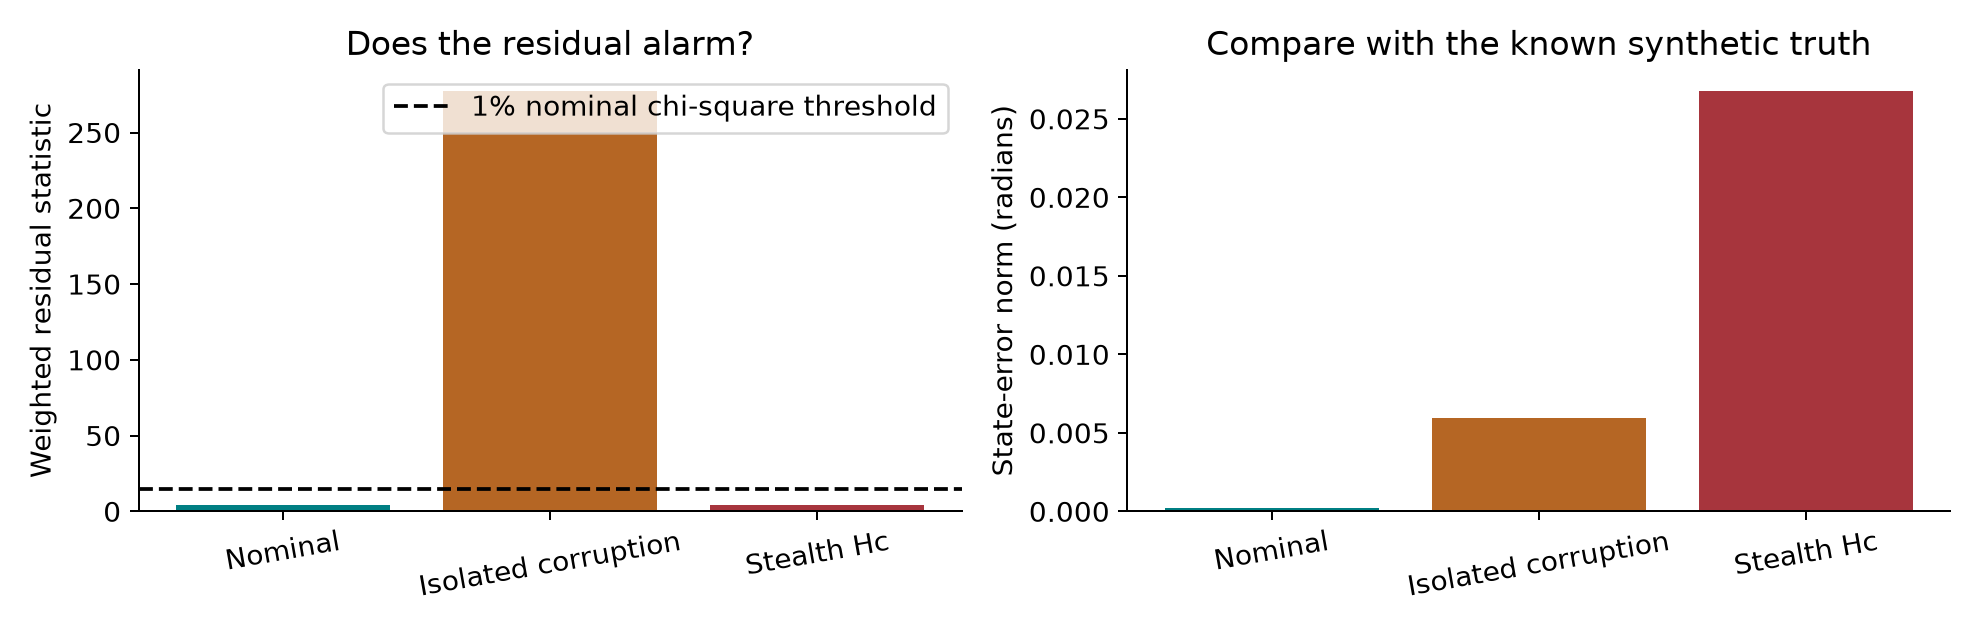

{'H': [[-10.0, 0.0, 0.0],
  [8.0, -8.0, 0.0],
  [0.0, 10.0, -10.0],
  [0.0, 0.0, -5.0],
  [18.0, -8.0, 0.0],
  [-8.0, 18.0, -10.0],
  [0.0, -10.0, 15.0],
  [1.0, 0.0, 0.0]],
 'known_synthetic_state': [-0.02, -0.05, -0.04]}

In [19]:
plot_cyber(cyber)
display({'H': cyber['measurement_model']['H'],
         'known_synthetic_state': cyber['measurement_model']['true_state']})


## C3–C4 · Recover a usable estimate, then verify control

The recovery demonstration assumes three additional protected independent angle measurements with $H_{\cal T}=I_3$. This set is observable but exactly determined: its residual degrees of freedom are zero, so it offers no chi-square redundancy. These are additional angle channels, not a subset of the original eight measurements. The code assumes trust; it does not authenticate devices.

The recovered estimate feeds an actual scalar DC redispatch problem. Let $u$ be a flexible injection balanced by the slack and $b$ its line-flow sensitivity:

$$\min_{0\leq u\leq0.5}\tfrac12u^2\quad\text{s.t.}\quad
-\overline f+0.01\leq F\hat x+b u\leq\overline f-0.01.$$

The 0.01 p.u. margin is a declared engineering choice, not a uncertainty guarantee. We check the proposed control against the known synthetic state in the same four-bus model. This demonstrates an estimator-to-controller link; it is not an AC cyber-resilience result for Greensboro.

**C3** contrasts the stealth-driven control with protected-estimate recovery. **C4** reads the actual recorded stage responses around this WLS/recovery method. In that integration experiment the numerical check passed but the Llama explanation requested `REVIEW`.


,source,status,flexible_injection_pu,objective,actual_violation_count
0,stealth estimate,PROPOSE,0.000000,0.000000,1
1,protected estimate,PROPOSE,0.121694,0.007405,0


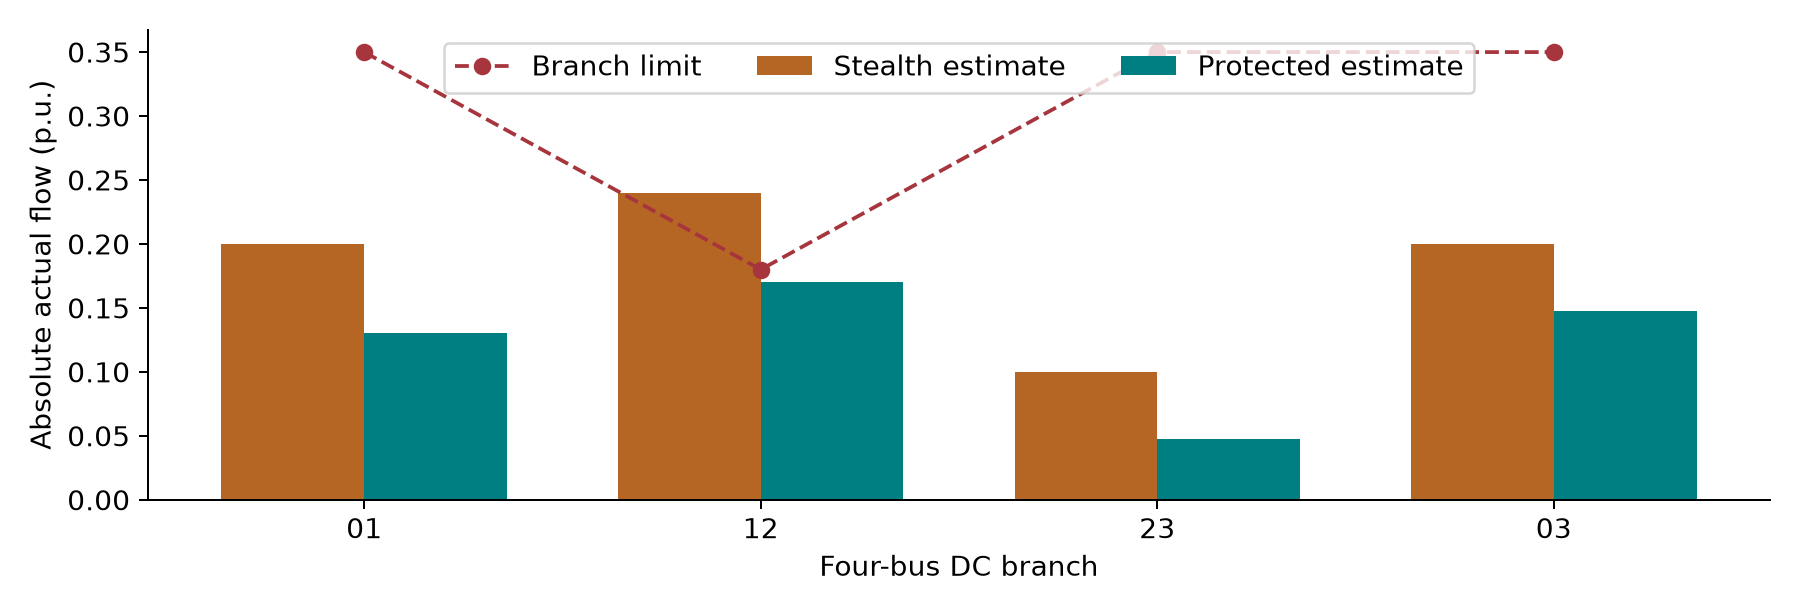

Protected-set residual degrees of freedom: 0


In [20]:
control_rows = [{'source': 'stealth estimate', **cyber['cases'][2]['control']},
                {'source': 'protected estimate', **cyber['trusted_recovery']['control']}]
table_rows(control_rows, ['source', 'status', 'flexible_injection_pu',
                         'objective', 'actual_violation_count'])
plot_trusted_control(cyber)
print('Protected-set residual degrees of freedom:', cyber['trusted_recovery']['chi_square']['degrees_of_freedom'])


In [21]:
cyber_agent = next(row for row in standard_stages['runs']
                  if row['case'] == 'cyber' and row['supervisor'] == 'agentic')
print('RECORDED WLS/recovery integration:', cyber_agent['status'])
show_trace(cyber_agent)
display(pd.DataFrame(cyber_comparison()))


RECORDED WLS/recovery integration: REVIEW


,stage,method,status,response_source
0,Awareness,Declared scenario/schema and model-coverage ch...,PASS,None
1,Planning,WLS_TRUSTED_REDISPATCH with fixed parameters,SOLVED,None
2,Execution proposal,Extract the numerical solution; no physical ac...,PROPOSED,None
3,Simulation,DC response model using known synthetic truth,EVALUATED,None
4,Verification,Declared numerical success and modeled-constra...,PASS,None
5,Recovery,One numerical attempt; unsuccessful verificati...,NOT_NEEDED,None
6,Explanation,Numerical metric card and separately labeled e...,REVIEW,None
7,Operator acknowledgment,Human review of immutable result identity,PENDING,None


,method,protected_measurements_supplied,candidate_injection_pu,simulated_actual_flow_1_2_pu,flow_1_2_limit_pu,simulated_violation_count,workflow_status,candidate_is_provisional,LLM_calls,equipment_operated
0,Compromised WLS + redispatch,False,0.000000,0.240000,0.18,1,NUMERICAL_PROPOSAL_ONLY,True,0,False
1,Conventional adaptive + protected data,True,0.121694,0.170461,0.18,0,MODEL_RECOMMEND,False,0,False
2,Agentic + same protected data,True,0.121694,0.170461,0.18,0,REVIEW,True,2,False


**Cyber comparison.** The WLS-only controller uses the corrupted readings and leaves actual branch 1–2 flow at **0.24000 p.u.**, above the **0.18 p.u.** limit. A conventional adaptive route with trusted-data recovery chooses $u=0.12169$ p.u. and reduces evaluated flow to **0.17046 p.u.** The agentic route invokes the same recovery and obtains the same numerical point, but its recorded Llama explanation requests REVIEW. The displayed agent control is a **provisional tool result**, not an accepted recommendation or dispatched action.

The benefit over WLS-only comes from trusted evidence and checked recovery. A strong conventional supervisor achieves the same numerical result. This experiment demonstrates visible tool routing and an explicit human handoff; it does not demonstrate better Llama attack detection or control. The trust assumption is supplied, not discovered by the agent.

**Exercise (3 min).** Explain how a stealth estimate passes the residual test but gives an unsafe action in this toy model. State what a protected measurement set contributes and what would fail if its rank dropped. Do not equate “no residual alarm” with “no attack.”

## F1–F2 · Compare evidence and perform operator review

**F1 first compares the current continuous SAC/MPC workflow records** for both backends and supervisors, including record timestamps, actual Llama call counts, rejected attempts and checked controls. It then displays a separately labeled historical R2 restoration comparison from the 32-run finite-catalog study. That historical study is not relabeled as continuous SAC, graph MILP or DC WLS. Timing is descriptive for one local run; MPC planning in V4, policy training and offline audits are separate costs.

When explaining the proposed framework, report: (1) the task interpretation and assumptions, (2) which established method computed the action, (3) the scope and result of verification, (4) any recovery or review decision, (5) the measured difference from a matched fixed supervisor. The strongest supported benefit in this package is improved coverage of a small authored language set; an autonomous superiority or safety claim is not established.


In [22]:
current_review = {'schema': SCHEMA, 'backend': BACKEND, 'created_utc': datetime.now(timezone.utc).isoformat(),
                  'fixed': fixed, 'agentic': agentic}
display(pd.DataFrame(comparison_rows(current_review)))
print('CURRENT continuous workflow above. HISTORICAL finite-action restoration comparison below:')
model_comparison = read_record('model_comparison.json')
display(pd.DataFrame([row for row in model_comparison['summary'] if row['case'] == 'R2'])[
    ['case', 'backend', 'method', 'model_status', 'final_review_status', 'pv_cap', 'tie', 'shed_fraction']])


,backend,supervisor,case,status,tool,control_a_b,P_kW,Q_kvar,max_current_pct_of_allowance,rejected_attempts,llama_calls,model_scope,record_created_utc,source
0,lindistflow3,fixed,P3_current_reserve,MODEL_RECOMMEND,SAC,"[0.33693869411945343, 0.030701177120208742]",2645.119216,241.017951,50.918255,0,0,MV-only phase network; internal LV constraints...,2026-09-27T16:13:39.114624+00:00,current in-memory run
1,lindistflow3,agentic,P3_current_reserve,MODEL_RECOMMEND,SAC,"[0.33693869411945343, 0.030701177120208742]",2645.119216,241.017951,50.918255,0,2,MV-only phase network; internal LV constraints...,2026-09-27T16:13:39.114624+00:00,current in-memory run
2,opendss,fixed,P3_current_reserve,MODEL_RECOMMEND,CONTINUOUS_MPC,"[0.3040791833492598, 0.04149291669866676]",2387.157382,325.737926,99.604410,1,0,Supplied full unbalanced AC feeder; protection...,2026-09-27T16:12:29.530248+00:00,saved classroom run
3,opendss,agentic,P3_current_reserve,MODEL_RECOMMEND,CONTINUOUS_MPC,"[0.3040791833492598, 0.04149291669866676]",2387.157382,325.737926,99.604410,1,3,Supplied full unbalanced AC feeder; protection...,2026-09-27T16:12:29.530248+00:00,saved classroom run


CURRENT continuous workflow above. HISTORICAL finite-action restoration comparison below:


,case,backend,method,model_status,final_review_status,pv_cap,tie,shed_fraction
0,R2,opendss,fixed,MODEL_RECOMMEND,AC_CHECK_PASSED,0.0,short,0.75
1,R2,opendss,agentic,MODEL_RECOMMEND,AC_CHECK_PASSED,0.0,short,0.75
2,R2,lindistflow3,fixed,MODEL_RECOMMEND,AC_CHECK_PASSED,0.0,short,0.75
3,R2,lindistflow3,agentic,MODEL_RECOMMEND,AC_CHECK_PASSED,0.0,short,0.75


**F2 operator task (5 min).** Save this run and open **Workshop_Operator_Dashboard.html**. It now uses the current continuous SAC/MPC classroom records. Select a model and supervisor; inspect the proposed P/Q, the current allowance, failed attempts, exact agent responses and model coverage. Read the displayed values back and acknowledge only if your review supports it, or request further review. This local unauthenticated record issues no equipment commands.

The partner model's entry is a saved classroom run, labeled with its timestamp. Compare like cases and distinguish coverage from approximation error. The original dashboard and 32-run study remain available as historical supplemental material.


In [23]:
run_record = {'schema': SCHEMA, 'backend': BACKEND, 'created_utc': datetime.now(timezone.utc).isoformat(),
    'agent_source': agent_source, 'voltage': voltage, 'continuous_checks': checks,
    'continuous_plans': plans, 'continuous_proposals': proposals,
    'fixed': fixed, 'agentic': agentic, 'restoration': restoration,
    'feeder_restoration': feeder_restoration, 'cyber': cyber}
output = save_workshop_run(run_record)
print('Saved new continuous-workflow evidence:', output.name)
display(HTML('<a href="Workshop_Operator_Dashboard.html" target="_blank">Open the current operator review screen</a>'))


Saved new continuous-workflow evidence: workshop_run_lindistflow3.json


## Continue reading and reproduce the lesson

The [general formulation appendix](appendix/General_Optimization_Formulations.md) gives complete notation, assumptions and primary references. The [scientific notes](appendix/Scientific_Notes.md) document data provenance, training and experimental limits. [Standard formulations](Standard_Formulations.ipynb) and the two audience notebooks retain the earlier studies in full. The LaTeX source, extracted code and [alignment map](latex_slides/Slide_Notebook_Map.md) are included; edit this notebook first and regenerate snippets before changing code slides.

The teaching progression—prerequisites, concepts, equations, executable checks and interpreted plots—was inspired by the [POWERUP three-phase Volt/VAR tutorial](https://epsrlab-ub.github.io/SmartInverter-3P-DOPF-POWERUP.jl/dev/tutorial_voltvar/). That tutorial studies autonomous droop encodings using Big-M, SOS2 and Heaviside approaches; our shared P/Q experiment is a different formulation. No results from that tutorial are presented as our measurements.


For this scientific-depth edition, use the [equation reading guide](appendix/Reading_Equations_and_Evidence.md), [recent agentic AI literature comparison](appendix/Recent_Agentic_AI_Literature.md) and [actual case-by-case agent responses](appendix/Case_Agent_Responses.md). The original numerical runs and checkpoint code are unchanged.
